# Final Project Unit3: EDA




# Step 1: Choose a Dataset

### Dataset Name: Space Rockets & Satellite Launches (1957–2026)

### Dataset Description:

This dataset contains information about rocket launches and satellites from 1957 to 2026. It includes 7,640 rocket launches and 28,056 satellite payload records. The dataset helps us explore space activities, rocket launches, and satellite deployment over time.

### Why I Selected This Dataset:

I selected this dataset because I am interested in space exploration. It contains a large amount of real-world data and allows me to explore interesting patterns and relationships using EDA.

**Source: https://mcval.org/launches/data**

#Step 2: Problem Definition

##1. Problem Definition and Understanding

We will work with the Space Rockets & Satellite Launches dataset to explore rocket launch activities, satellite information, and orbital characteristics.

The dataset consists of two CSV files: launches.csv and satellites.csv.

###1.1 Problem Definition

Our main goal is to explore the datasets, understand how space launch activities have changed over time, identify the most active launch organizations, analyze mission success rates, and discover patterns in satellite orbits.

###1.2 Key Questions

During the EDA, we will focus on answering questions such as:

1. How has the number of rocket launches changed over the years?
2. How many rocket launches have been recorded since 1957?
3. Which organizations have conducted the most rocket launches?
4. What is the success rate of rocket launches?
5. How many satellites are recorded in the dataset?
6. What are the most common orbital categories?
7. How does satellite orbital altitude vary?

###1.3 Expected Insights

Through this analysis, we expect to discover:

* How rocket launch activity has increased or changed over time.
* Which years recorded the highest number of launches.
* Which organizations are the most active in space launches.
* Whether rocket launch success rates have improved over the years.
* How satellites are distributed across different orbital categories.
* Which orbital altitudes are most common among satellites.
* Whether there is a relationship between satellite altitude and orbital period.

These expected insights will help us better understand the development of space activities and identify interesting patterns in the datasets.

#Step 3: Data Loading & Structure

In [58]:
# import libaries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [59]:
# Download the dataset
Data1_launches = pd.read_csv('/content/launches.csv')
Data2_satellites = pd.read_csv('/content/satellites.csv')

In [60]:
# data merging
df = pd.merge(
   Data1_launches,
   Data2_satellites,
   on = 'launch_id',
   how = 'left',
   suffixes = ('_sat','_launch')
)

In [61]:
#Disp;ay the first 5 rows
df.head()

,launch_id,date_utc,cospar_launch_sat,rocket_sat,provider,provider_type,site,site_country,pad,outcome,...,user,operator,operator_group,registered_to,orbit_centre,orbit_withheld,period_min,inclination_deg,apogee_km,perigee_km
0,e3df2ecd-c239-472f-95e4-2b89b4f75800,1957-10-04 19:28,1957-001,Sputnik 8K74PS,Soviet Space Program,government,Baikonur Cosmodrome,Kazakhstan,1/5,success,...,civil government,OKB-1 im. S.P. Korolev,OKB-1 im. S.P. Korolev,CIS,EA,no,96.1,65.0,1080.0,64.0
1,f8c9f344-a6df-4f30-873a-90fe3a7840b3,1957-11-03 02:30,1957-002,Sputnik 8K74PS,Soviet Space Program,government,Baikonur Cosmodrome,Kazakhstan,1/5,success,...,civil government,OKB-1 im. S.P. Korolev,OKB-1 im. S.P. Korolev,CIS,EA,no,103.7,65.3,1659.0,211.0
2,535c1a09-97c8-4f96-bb64-6336d4bcb1fb,1957-12-06 16:44,NaN,Vanguard,US Navy,government,Cape Canaveral Space Force Station,USA,Launch Complex 18A,failure,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1b9e28d0-c531-44b0-9b37-244e62a6d3f4,1958-02-01 03:47,1958-001,Juno-I,Army Ballistic Missile Agency,government,Cape Canaveral Space Force Station,USA,Launch Complex 26A,success,...,defence,U.S. Army Ballistic Missile Agency,United States Army,US,EA,no,88.5,33.2,215.0,183.0
4,48bc7deb-b2e1-46c2-ab63-0ce00fbd192b,1958-02-05 07:33,NaN,Vanguard,US Navy,government,Cape Canaveral Space Force Station,USA,Launch Complex 18A,failure,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [62]:
df.shape

(28736, 34)

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28736 entries, 0 to 28735
Data columns (total 34 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   launch_id             28736 non-null  object 
 1   date_utc              28736 non-null  object 
 2   cospar_launch_sat     28069 non-null  object 
 3   rocket_sat            28736 non-null  object 
 4   provider              28736 non-null  object 
 5   provider_type         28736 non-null  object 
 6   site                  28736 non-null  object 
 7   site_country          28736 non-null  object 
 8   pad                   28736 non-null  object 
 9   outcome               28736 non-null  object 
 10  mission               28736 non-null  object 
 11  mission_type          27884 non-null  object 
 12  orbit                 28735 non-null  object 
 13  payloads_catalogued   28736 non-null  int64  
 14  wikipedia             6979 non-null   object 
 15  webcast            

In [64]:
df.describe()

,payloads_catalogued,norad_id,period_min,inclination_deg,apogee_km,perigee_km
count,28736.000000,28056.000000,27574.000000,27562.000000,2.757400e+04,27574.000000
mean,31.832336,49036.198496,238.511181,63.373362,3.803637e+03,2646.194567
std,53.431603,21521.739731,4240.014230,24.895863,3.877304e+04,8805.596162
min,0.000000,2.000000,86.300000,0.000000,9.500000e+01,5.000000
25%,3.000000,40255.000000,91.200000,51.600000,3.530000e+02,299.000000
50%,23.000000,54140.500000,93.900000,53.200000,4.670000e+02,465.000000
75%,40.000000,63551.250000,96.100000,87.900000,5.790000e+02,560.000000
max,417.000000,101074.000000,486100.200000,150.900000,4.082876e+06,324574.000000


In [65]:
df.isnull().sum()

,0
launch_id,0
date_utc,0
cospar_launch_sat,667
rocket_sat,0
provider,0
provider_type,0
site,0
site_country,0
pad,0
outcome,0


#Step 4: Data Cleaning

In [66]:
# Rename the columns
df = df.rename(columns={
    # Satellite Information
    'norad_id': 'satellite_norad_id',
    'cospar_id': 'satellite_cospar_id',
    'name': 'satellite_name',
    'launch_date': 'satellite_launch_date',
    'decay_date': 'satellite_decay_date',
    'user': 'satellite_user_type',
    'operator': 'satellite_operator',
    'operator_group': 'satellite_operator_group',
    'registered_to': 'satellite_registration',
    'orbit_centre': 'orbit_center',
    'orbit_withheld': 'orbital_data_withheld',

    # Satellite Orbit Information
    'period_min': 'orbital_period_minutes',
    'inclination_deg': 'orbital_inclination_degrees',
    'apogee_km': 'highest_orbital_altitude_km',
    'perigee_km': 'lowest_orbital_altitude_km',

    # Rocket Launch Information
    'date_utc': 'rocket_launch_date_utc',
    'rocket_launch': 'launch_rocket_name',
    'rocket_sat': 'satellite_record_rocket_name',
    'provider': 'launch_organization',
    'provider_type': 'launch_organization_type',
    'site': 'launch_site',
    'site_country': 'launch_country',
    'pad': 'launch_pad',
    'outcome': 'launch_outcome',
    'mission': 'mission_name',
    'mission_type': 'mission_category',
    'orbit': 'launch_orbit_category',
    'payloads_catalogued': 'catalogued_payload_count',
    'wikipedia': 'wikipedia_link',
    'webcast': 'launch_video_link',

    # Launch Identifiers
    'cospar_launch_sat': 'satellite_record_launch_cospar_id',
    'cospar_launch_launch': 'launch_cospar_id'
})

df.head()

,launch_id,rocket_launch_date_utc,satellite_record_launch_cospar_id,satellite_record_rocket_name,launch_organization,launch_organization_type,launch_site,launch_country,launch_pad,launch_outcome,...,satellite_user_type,satellite_operator,satellite_operator_group,satellite_registration,orbit_center,orbital_data_withheld,orbital_period_minutes,orbital_inclination_degrees,highest_orbital_altitude_km,lowest_orbital_altitude_km
0,e3df2ecd-c239-472f-95e4-2b89b4f75800,1957-10-04 19:28,1957-001,Sputnik 8K74PS,Soviet Space Program,government,Baikonur Cosmodrome,Kazakhstan,1/5,success,...,civil government,OKB-1 im. S.P. Korolev,OKB-1 im. S.P. Korolev,CIS,EA,no,96.1,65.0,1080.0,64.0
1,f8c9f344-a6df-4f30-873a-90fe3a7840b3,1957-11-03 02:30,1957-002,Sputnik 8K74PS,Soviet Space Program,government,Baikonur Cosmodrome,Kazakhstan,1/5,success,...,civil government,OKB-1 im. S.P. Korolev,OKB-1 im. S.P. Korolev,CIS,EA,no,103.7,65.3,1659.0,211.0
2,535c1a09-97c8-4f96-bb64-6336d4bcb1fb,1957-12-06 16:44,NaN,Vanguard,US Navy,government,Cape Canaveral Space Force Station,USA,Launch Complex 18A,failure,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1b9e28d0-c531-44b0-9b37-244e62a6d3f4,1958-02-01 03:47,1958-001,Juno-I,Army Ballistic Missile Agency,government,Cape Canaveral Space Force Station,USA,Launch Complex 26A,success,...,defence,U.S. Army Ballistic Missile Agency,United States Army,US,EA,no,88.5,33.2,215.0,183.0
4,48bc7deb-b2e1-46c2-ab63-0ce00fbd192b,1958-02-05 07:33,NaN,Vanguard,US Navy,government,Cape Canaveral Space Force Station,USA,Launch Complex 18A,failure,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [67]:
df.columns.tolist()

['launch_id',
 'rocket_launch_date_utc',
 'satellite_record_launch_cospar_id',
 'satellite_record_rocket_name',
 'launch_organization',
 'launch_organization_type',
 'launch_site',
 'launch_country',
 'launch_pad',
 'launch_outcome',
 'mission_name',
 'mission_category',
 'launch_orbit_category',
 'catalogued_payload_count',
 'wikipedia_link',
 'launch_video_link',
 'satellite_norad_id',
 'satellite_cospar_id',
 'satellite_name',
 'satellite_launch_date',
 'satellite_decay_date',
 'launch_cospar_id',
 'launch_rocket_name',
 'launch_provider',
 'satellite_user_type',
 'satellite_operator',
 'satellite_operator_group',
 'satellite_registration',
 'orbit_center',
 'orbital_data_withheld',
 'orbital_period_minutes',
 'orbital_inclination_degrees',
 'highest_orbital_altitude_km',
 'lowest_orbital_altitude_km']

In [68]:
df.shape

(28736, 34)

In [69]:
# Handle missing value
missing_value_df = df.isna().mean()  * 100

print(missing_value_df[missing_value_df > 0])

high_missing = missing_value_df[missing_value_df > 5]
print(high_missing)


satellite_record_launch_cospar_id     2.321130
mission_category                      2.964922
launch_orbit_category                 0.003480
wikipedia_link                       75.713391
launch_video_link                    25.922188
satellite_norad_id                    2.366370
satellite_cospar_id                   2.366370
satellite_name                        2.366370
satellite_launch_date                 2.366370
satellite_decay_date                 73.086024
launch_cospar_id                      2.366370
launch_rocket_name                    2.366370
launch_provider                       2.366370
satellite_user_type                   2.366370
satellite_operator                    5.247773
satellite_operator_group              5.247773
satellite_registration                2.366370
orbit_center                          2.366370
orbital_data_withheld                 2.366370
orbital_period_minutes                4.043708
orbital_inclination_degrees           4.085468
highest_orbit

In [70]:
df['satellite_operator_group'].isnull().sum()

np.int64(1508)

In [71]:
# Handling Missing Values

# Drop unnecessary columns
df = df.drop(columns=['wikipedia_link', 'launch_video_link'])

# Fill missing categorical values
df['mission_category'] = df['mission_category'].fillna('Unknown')
df['satellite_operator'] = df['satellite_operator'].fillna('Unknown')
df['satellite_operator_group'] = df['satellite_operator_group'].fillna('Unknown')

# Create datasets for different analyses
launch_df = df.drop_duplicates(subset=['launch_id']).copy()

satellite_df = df.dropna(subset=['satellite_norad_id']).copy()
#drob missing value
orbit_df = satellite_df.dropna(
    subset=[
        'highest_orbital_altitude_km',
        'lowest_orbital_altitude_km',
        'orbital_period_minutes'
    ]
).copy()

# Check results
print("Original dataset:", df.shape)
print("Launch dataset:", launch_df.shape)
print("Satellite dataset:", satellite_df.shape)
print("Orbit dataset:", orbit_df.shape)


Original dataset: (28736, 32)
Launch dataset: (7640, 32)
Satellite dataset: (28056, 32)
Orbit dataset: (27574, 32)


First, I checked the percentage of missing values in each column.

I found that some columns had more than 5% missing values.

I removed wikipedia_link and launch_video_link because I didn’t need them for my analysis.

For categorical columns, I filled some missing values with “Unknown”.

Then I created three datasets for different analyses.

I used drop_duplicates() in launch_df to avoid counting the same rocket launch more than once.

I used dropna() in satellite_df to remove rows without satellite IDs.

Finally, I created orbit_df by removing rows with missing orbital measurements because I needed these values for my charts.

I found that satellite_decay_date has about 73% missing values.

I kept this column because it is important and shows the date when a satellite decayed or left its orbit.

I couldn’t fill the missing values using the mean or median because that would create incorrect dates. I also didn’t want to delete the column because it contains useful information.

In [72]:
# Check duplicates
duplicates = df.duplicated().sum()

print("Duplicates:", duplicates)
print("Dataset Shape:", df.shape)

Duplicates: 0
Dataset Shape: (28736, 32)


In [73]:
df.dtypes

,0
launch_id,object
rocket_launch_date_utc,object
satellite_record_launch_cospar_id,object
satellite_record_rocket_name,object
launch_organization,object
launch_organization_type,object
launch_site,object
launch_country,object
launch_pad,object
launch_outcome,object


In [74]:
# convert to datatime
df['rocket_launch_date_utc'] = pd.to_datetime(df['rocket_launch_date_utc'],errors="coerce")
df['rocket_launch_date_utc']

,rocket_launch_date_utc
0,1957-10-04 19:28:00
1,1957-11-03 02:30:00
2,1957-12-06 16:44:00
3,1958-02-01 03:47:00
4,1958-02-05 07:33:00
...,...
28731,2026-10-14 11:40:00
28732,2026-10-14 11:40:00
28733,2026-10-14 11:40:00
28734,2026-10-14 11:40:00


In [75]:
# convert to datatime
df['satellite_launch_date'] = pd.to_datetime(df['satellite_launch_date'],errors="coerce")
df['satellite_launch_date']

,satellite_launch_date
0,1957-10-04
1,1957-11-03
2,NaT
3,1958-02-01
4,NaT
...,...
28731,2026-10-14
28732,2026-10-14
28733,2026-10-14
28734,2026-10-14


In [76]:
# convert to datatime
df['satellite_decay_date'] = pd.to_datetime(df['satellite_decay_date'],errors="coerce")
df['satellite_decay_date']

,satellite_decay_date
0,1958-01-03
1,1958-04-14
2,NaT
3,1970-03-31
4,NaT
...,...
28731,NaT
28732,NaT
28733,NaT
28734,NaT


I converted some columns to datetime. The missing values became NaT, and any invalid dates were also converted to NaT.

I kept the missing values in satellite_decay_date because this column represents the date when a satellite decayed or left its orbit. I couldn’t fill these values using the mean or median because that would give incorrect dates.

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28736 entries, 0 to 28735
Data columns (total 32 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   launch_id                          28736 non-null  object        
 1   rocket_launch_date_utc             28736 non-null  datetime64[ns]
 2   satellite_record_launch_cospar_id  28069 non-null  object        
 3   satellite_record_rocket_name       28736 non-null  object        
 4   launch_organization                28736 non-null  object        
 5   launch_organization_type           28736 non-null  object        
 6   launch_site                        28736 non-null  object        
 7   launch_country                     28736 non-null  object        
 8   launch_pad                         28736 non-null  object        
 9   launch_outcome                     28736 non-null  object        
 10  mission_name                      

In [78]:
df.describe()

,rocket_launch_date_utc,catalogued_payload_count,satellite_norad_id,satellite_launch_date,satellite_decay_date,orbital_period_minutes,orbital_inclination_degrees,highest_orbital_altitude_km,lowest_orbital_altitude_km
count,28736,28736.000000,28056.000000,28056,7734,27574.000000,27562.000000,2.757400e+04,27574.000000
mean,2013-10-13 11:05:56.913975552,31.832336,49036.198496,2014-04-30 13:06:31.103507200,2008-01-02 22:40:52.133436928,238.511181,63.373362,3.803637e+03,2646.194567
min,1957-10-04 19:28:00,0.000000,2.000000,1957-10-04 00:00:00,1958-01-03 00:00:00,86.300000,0.000000,9.500000e+01,5.000000
25%,2010-12-08 15:43:00,3.000000,40255.000000,2012-11-30 18:00:00,1987-07-22 18:00:00,91.200000,51.600000,3.530000e+02,299.000000
50%,2022-09-05 02:09:00,23.000000,54140.500000,2022-10-14 00:00:00,2022-04-20 00:00:00,93.900000,53.200000,4.670000e+02,465.000000
75%,2025-03-26 15:30:00,40.000000,63551.250000,2025-04-07 00:00:00,2024-12-12 18:00:00,96.100000,87.900000,5.790000e+02,560.000000
max,2026-10-16 00:01:00,417.000000,101074.000000,2026-10-14 00:00:00,2026-10-17 00:00:00,486100.200000,150.900000,4.082876e+06,324574.000000
std,NaN,53.431603,21521.739731,NaN,NaN,4240.014230,24.895863,3.877304e+04,8805.596162


In [79]:
df.to_csv('Space_Cleaned2.csv', index=False)

# Outliers

In [80]:
#cheek outliers
orbit_df.nlargest(
    10, 'highest_orbital_altitude_km'
)[[
    'satellite_name',
    'highest_orbital_altitude_km',
    'lowest_orbital_altitude_km',
    'orbital_period_minutes'
]]

,satellite_name,highest_orbital_altitude_km,lowest_orbital_altitude_km,orbital_period_minutes
24420,ESCAPADE BLUE,4082876.0,185.0,486100.2
24421,ESCAPADE GOLD,4082876.0,185.0,486100.2
6245,GENESIS SRC,1373247.0,5.0,95688.0
18383,DRO-A,760436.0,324574.0,67449.7
1163,APOLLO 8,544356.0,215.0,24399.4
52,LUNA 3,499998.0,500.0,21563.2
754,EXPLORER 33 (AIMP-D),480762.0,265679.0,38792.4
18384,DRO-B,431608.0,181234.0,29017.4
9119,BERESHEET,407521.0,1261.0,16049.8
8803,QUEQIAO,383110.0,395.0,14628.0


I used nlargest(10) to display the 10 highest orbital altitudes and check which satellites have these values.

I also used IQR to detect outliers. I kept the outliers because they may represent real orbital measurements.

In [81]:
# Calculate Q1 and Q3
Q1 = orbit_df['highest_orbital_altitude_km'].quantile(0.25)
Q3 = orbit_df['highest_orbital_altitude_km'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find outliers
outliers = orbit_df[
    (orbit_df['highest_orbital_altitude_km'] < lower_bound) |
    (orbit_df['highest_orbital_altitude_km'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

Q1: 353.0
Q3: 579.0
IQR: 226.0
Lower Bound: 14.0
Upper Bound: 918.0
Number of Outliers: 4699


I used the IQR method to detect outliers in highest_orbital_altitude_km.

I found some extremely high orbital altitudes compared to most satellite records.

I decided to keep the outliers because they may represent real orbital measurements.

# Step 5 Exploratory Data Analysis (EDA)
## Univariate

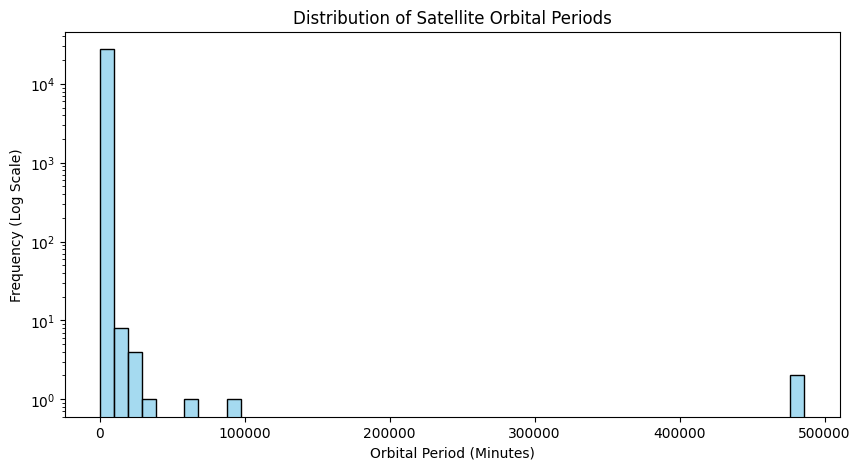

In [82]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=satellite_df,
    x='orbital_period_minutes',
    bins=50,
    color='skyblue',
    edgecolor='black'
)

plt.yscale('log')

plt.title('Distribution of Satellite Orbital Periods')
plt.xlabel('Orbital Period (Minutes)')
plt.ylabel('Frequency (Log Scale)')
plt.show()

In the first chart, I chose a Histogram because orbital_period_minutes is a numerical column, and I wanted to understand how satellite orbital periods are distributed.

I found that most satellites have relatively short orbital periods, while a few have very high values. This means the distribution is right-skewed.

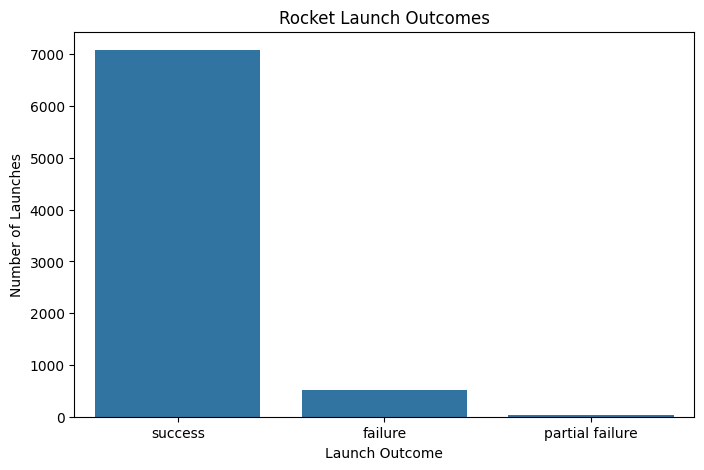

In [83]:
plt.figure(figsize=(8,5))
sns.countplot(x = 'launch_outcome',data = launch_df)
plt.title('Rocket Launch Outcomes')
plt.xlabel('Launch Outcome')
plt.ylabel('Number of Launches')
plt.show()

In the second chart, I chose a Countplot because launch_outcome is a categorical column that shows the result of rocket launches. I wanted to count the number of launches in each category.

I found that successful rocket launches are much more common than failed or partially failed launches.

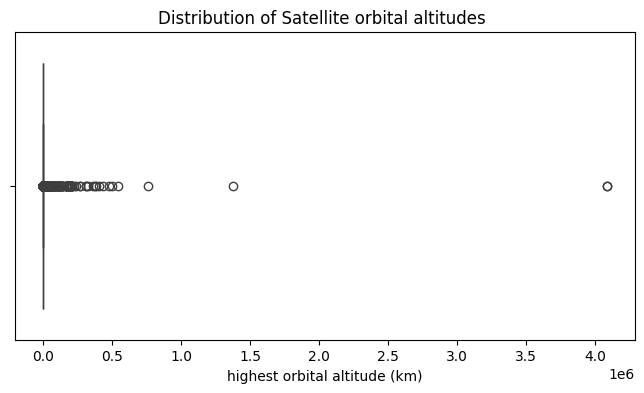

In [84]:
plt.figure(figsize=(8,4))
sns.boxplot(x = 'highest_orbital_altitude_km', data = satellite_df)
plt.title('Distribution of Satellite orbital altitudes ')
plt.xlabel('highest orbital altitude (km)')
plt.show()
#,showfliers = False

In the third chart, I chose a Boxplot using the highest_orbital_altitude_km column, which shows the highest orbital altitude of satellites.

I used it to identify outliers and understand the spread of the data.

I found that there are extremely high outliers, which make the box and median difficult to see clearly.

#Step 6 Bivariate

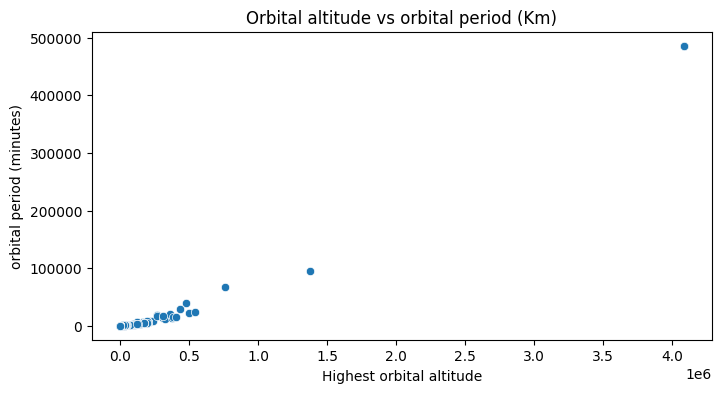

In [85]:
plt.figure(figsize=(8,4))
sns.scatterplot(x = 'highest_orbital_altitude_km' , y = 'orbital_period_minutes', data = orbit_df)
plt.title('Orbital altitude vs orbital period (Km)')
plt.xlabel('Highest orbital altitude')
plt.ylabel('orbital period (minutes)')
plt.show()

In the fourth chart, I chose a Scatterplot, and the analysis type is Bivariate.

The X-axis uses highest_orbital_altitude_km, which shows the highest orbital altitude of satellites in kilometers.

The Y-axis uses orbital_period_minutes, which shows the time a satellite takes to complete one orbit in minutes.

I chose this chart because I wanted to know if there is a relationship between satellite altitude and orbital period.

I found that as orbital altitude increases, orbital period generally increases too. This means there is a positive relationship between them.

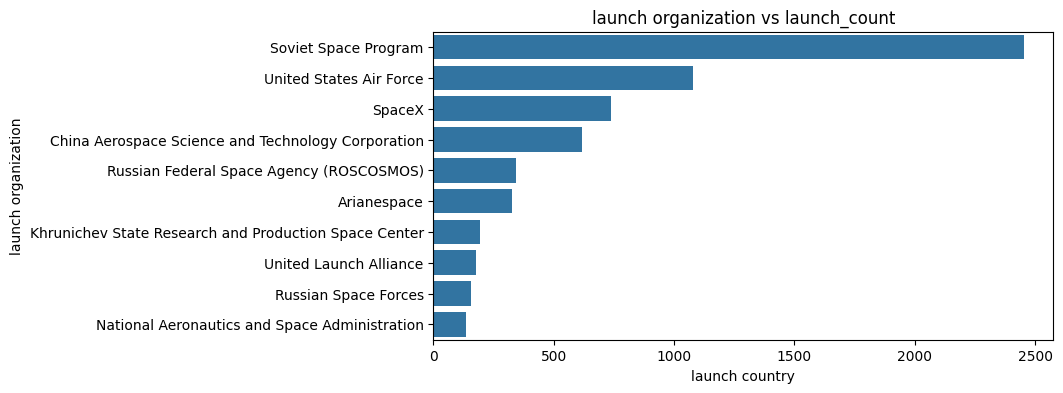

In [86]:
Top_10 = (launch_df['launch_organization'].value_counts().head(10).reset_index())
Top_10.columns=['launch_organization','launch_count']
plt.figure(figsize=(8,4))
sns.barplot(x='launch_count', y='launch_organization',data = Top_10)
plt.title('launch organization vs launch_count')
plt.xlabel('launch country')
plt.ylabel('launch organization')
plt.show()

In the fifth chart, I chose a Barplot, and the analysis type is Bivariate.

The X-axis uses launch_count, which shows the number of rocket launches.

The Y-axis uses launch_organization, which shows the organizations responsible for rocket launches.

The data types are Numerical and Categorical.

I chose this chart because I wanted to compare the number of rocket launches between different organizations.

I found that the Soviet Space Program recorded the highest number of launches in our dataset, followed by the United States Air Force and then SpaceX.

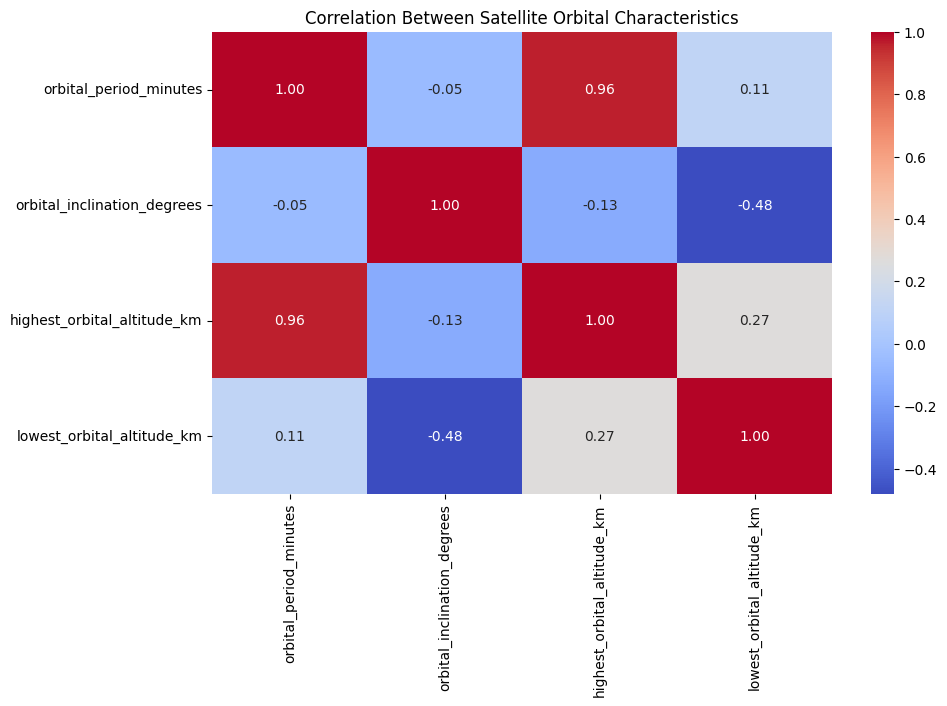

In [87]:
# Correlation Heatmap

columns = [
    'orbital_period_minutes',
    'orbital_inclination_degrees',
    'highest_orbital_altitude_km',
    'lowest_orbital_altitude_km'
]

corr = satellite_df[columns].corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
)

plt.title('Correlation Between Satellite Orbital Characteristics')
plt.show()

In the sixth chart, I chose a Correlation Heatmap, and the analysis type is Multivariate.

The data type is Numerical, and I used 4 columns:
orbital_period_minutes, orbital_inclination_degrees, highest_orbital_altitude_km, and lowest_orbital_altitude_km.

I chose this chart because I wanted to know the strength and direction of the linear relationship between several numerical columns.

I found that the strongest relationship was between orbital_period_minutes and highest_orbital_altitude_km, with a correlation of +0.96, which means a very strong positive relationship.

I also found that the relationship between orbital_inclination_degrees and lowest_orbital_altitude_km was -0.48, which means a moderate negative relationship.

The rest of the relationships were weak.

# Step 7 Multivariate

In [88]:
print(satellite_df.select_dtypes(include='object').columns.tolist())

['launch_id', 'rocket_launch_date_utc', 'satellite_record_launch_cospar_id', 'satellite_record_rocket_name', 'launch_organization', 'launch_organization_type', 'launch_site', 'launch_country', 'launch_pad', 'launch_outcome', 'mission_name', 'mission_category', 'launch_orbit_category', 'satellite_cospar_id', 'satellite_name', 'satellite_launch_date', 'satellite_decay_date', 'launch_cospar_id', 'launch_rocket_name', 'launch_provider', 'satellite_user_type', 'satellite_operator', 'satellite_operator_group', 'satellite_registration', 'orbit_center', 'orbital_data_withheld']


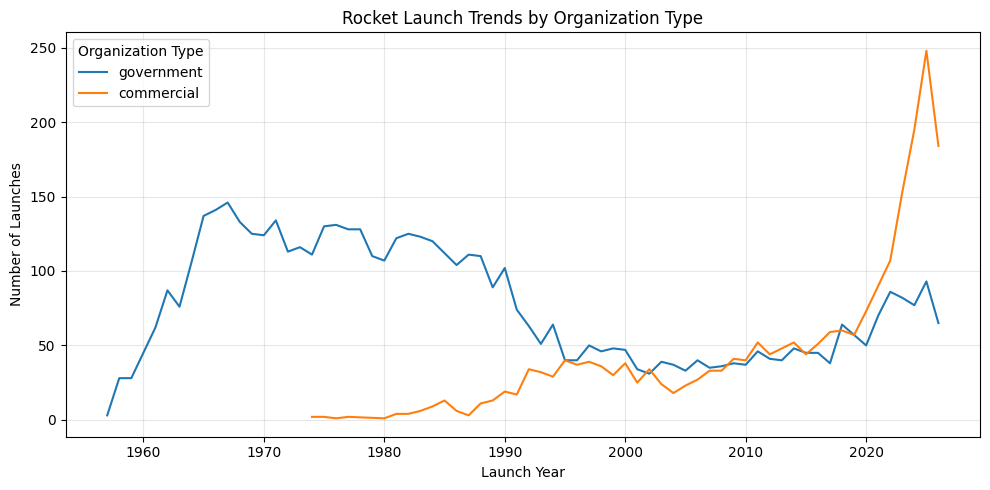

In [89]:
#7
aunch_df = df.drop_duplicates(subset='launch_id').copy()

launch_df['launch_year'] = pd.to_datetime(
    launch_df['rocket_launch_date_utc']
).dt.year

yearly_data = (
    launch_df.groupby(
        ['launch_year', 'launch_organization_type']
    )
    .size()
    .reset_index(name='launch_count')
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_data,
    x='launch_year',
    y='launch_count',
    hue='launch_organization_type'
)

plt.title('Rocket Launch Trends by Organization Type')
plt.xlabel('Launch Year')
plt.ylabel('Number of Launches')
plt.legend(title='Organization Type')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In the seventh chart, I chose a Lineplot, and the analysis type is Multivariate.

I used launch_year for X, launch_count for Y, and launch_organization_type for the colors.

I chose it because I wanted to know how the number of rocket launches changed over the years for different organization types.

This chart helps me see the increase and decrease in launches over time and compare different organizations.

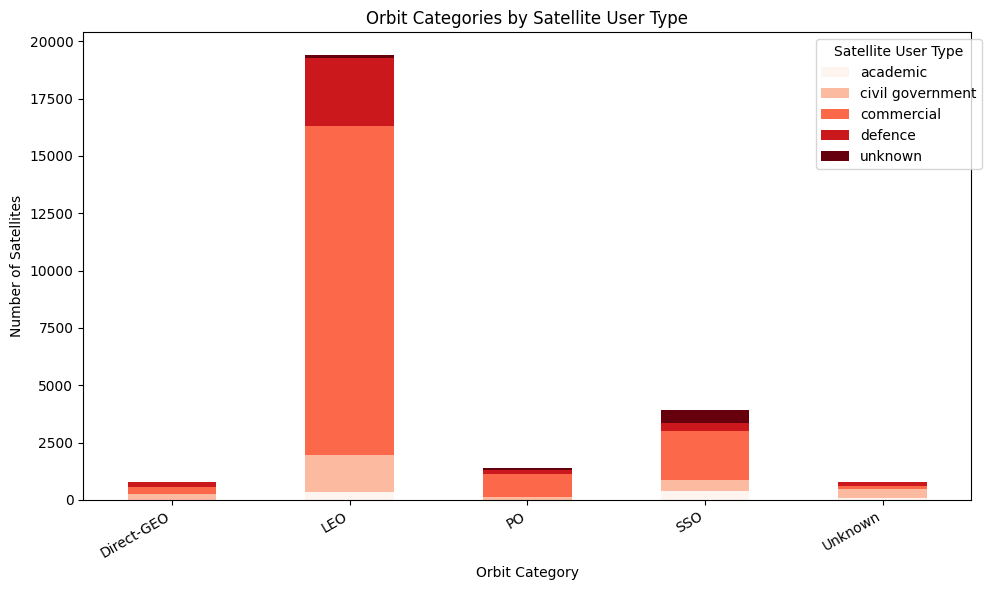

In [90]:
#8
satellite_df = df.dropna(
    subset=['satellite_norad_id']
).drop_duplicates(
    subset=['satellite_norad_id']
).copy()

# Select top 5 orbit categories
top_orbits = (
    satellite_df['launch_orbit_category']
    .value_counts()
    .head(5)
    .index
)

chart8_df = satellite_df[
    satellite_df['launch_orbit_category'].isin(top_orbits)
].copy()

chart8_df['satellite_user_type'] = (
    chart8_df['satellite_user_type'].fillna('Unknown')
)

# Count satellites by orbit category and user type
orbit_users = pd.crosstab(
    chart8_df['launch_orbit_category'],
    chart8_df['satellite_user_type']
)

# Plot
ax = orbit_users.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='Reds'
)

plt.title('Orbit Categories by Satellite User Type')
plt.xlabel('Orbit Category')
plt.ylabel('Number of Satellites')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Satellite User Type', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In the eighth chart, I chose a Stacked Bar Chart, and the analysis type is Multivariate.

I used launch_orbit_category for X, satellite_count for Y, and satellite_user_type for the colors.

I chose it because I wanted to know which orbit categories are more common and compare them between different satellite user types.

This chart helps me see how satellites are distributed across orbit categories and user types.

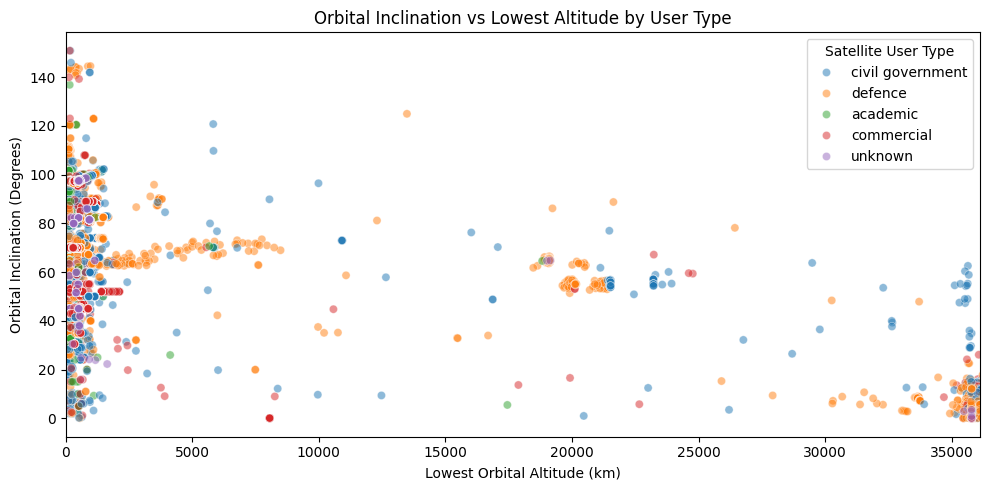

In [91]:
#9
chart9_df = satellite_df.dropna(
    subset=[
        'lowest_orbital_altitude_km',
        'orbital_inclination_degrees',
        'satellite_user_type'
    ]
).copy()

# Zoom the chart without deleting data
limit = chart9_df['lowest_orbital_altitude_km'].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=chart9_df,
    x='lowest_orbital_altitude_km',
    y='orbital_inclination_degrees',
    hue='satellite_user_type',
    alpha=0.5,
    s=35
)

plt.xlim(0, limit)

plt.title('Orbital Inclination vs Lowest Altitude by User Type')
plt.xlabel('Lowest Orbital Altitude (km)')
plt.ylabel('Orbital Inclination (Degrees)')
plt.legend(title='Satellite User Type')
plt.tight_layout()
plt.show()

In the ninth chart, I chose a Scatterplot with Hue, and the analysis type is Multivariate.

I used lowest_orbital_altitude_km for X, orbital_inclination_degrees for Y, and satellite_user_type for the colors.

I chose it because I wanted to know if there is a relationship between the lowest orbital altitude and orbital inclination, and if it changes between different satellite user types.

This chart helps me compare the relationship between these variables.

# Insights Summary

###1. Patterns

I found that the number of rocket launches has changed over the years. Based on my dashboard results, 2025 had the highest number of launches, with 341 launches.

Our dataset contains 7,640 rocket launches recorded since 1957.

I also found that the Soviet Space Program had the highest number of launches, followed by the US Air Force and SpaceX.

Most rocket launches were successful, while failures were much less common.

The dataset also contains 28,056 satellite records.

###2. Interesting Relationships

I found a strong positive relationship between orbital period and highest orbital altitude, with a correlation of +0.96.

This means that satellites with higher orbital altitudes generally have longer orbital periods.

I also found that the relationship between orbital inclination and lowest orbital altitude was -0.48, which means a moderate negative relationship.

###3. Outliers

I found some very high outliers in satellite orbital altitude compared to most satellites.

I kept these values because they may represent real orbital measurements, and I didn’t want to remove important information without checking them.

###4. Key Takeaways

I found that most satellites have relatively short orbital periods, while a few have much longer periods.

Orbital categories are not equally common, and I used the Stacked Bar Chart to compare them across different satellite user types.

Overall, I learned that rocket launch activity has changed over time, most recorded launches were successful, and satellite orbital characteristics are related.

# Answers to the 7 key Questions

1. How has the number of rocket launches changed over the years?

I found that the number of rocket launches has changed over the years. Based on my dashboard results, 2025 had the highest number of launches, with 341 launches.

2. How many rocket launches have been recorded since 1957?

I found that our dataset contains 7,640 recorded rocket launches since 1957.

3. Which organizations have conducted the most rocket launches?

I found that the Soviet Space Program had the highest number of rocket launches, followed by the US Air Force and SpaceX.

4. What is the success rate of rocket launches?

I found that 92.71% of rocket launches were successful, while 6.85% failed and only 0.45% partially failed.

This means most rocket launches in our dataset were successful.

5. How many satellites are recorded in the dataset?

I found that our dataset contains 28,056 satellite records.

6. What are the most common orbital categories?

I found that LEO was the most common orbit category in our dataset, with 19,423 satellite records.

It was followed by SSO with 3,927 records and PO with 1,401 records.

This shows that LEO is much more common than the other orbit categories in our dataset.

7. How does satellite orbital altitude vary?

I found that most satellites have relatively low orbital altitudes, while a few have extremely high values.

I also found a strong positive relationship between orbital altitude and orbital period, with a correlation of +0.96.

In [92]:
# Correlation using all values

original_corr = orbit_df[
    'highest_orbital_altitude_km'
].corr(
    orbit_df['orbital_period_minutes']
)

# Create a separate dataset without top 1% extremes

alt_limit = orbit_df[
    'highest_orbital_altitude_km'
].quantile(0.99)

period_limit = orbit_df[
    'orbital_period_minutes'
].quantile(0.99)

orbit_check = orbit_df[
    (orbit_df['highest_orbital_altitude_km'] <= alt_limit) &
    (orbit_df['orbital_period_minutes'] <= period_limit)
].copy()

# Calculate correlation again

new_corr = orbit_check[
    'highest_orbital_altitude_km'
].corr(
    orbit_check['orbital_period_minutes']
)

print("Original Correlation:", round(original_corr, 3))
print("Correlation without top 1%:", round(new_corr, 3))

Original Correlation: 0.964
Correlation without top 1%: 0.99
